# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from matplotlib.colors import ListedColormap
%matplotlib inline

dataset = pd.read_csv('car_purchase_data.csv')

### Step 2: Split features and target

In [62]:
#Please write the code here
y = dataset['Purchased']
x = dataset[['Age', 'Salary']]

### Step 3: Train/Test Split

In [63]:
#Please write the code here
# Using a 25% test size and a random state for reproducibility 
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)


### Step 4: Feature Scaling

In [64]:
#Please write the code here

sc = StandardScaler()
# Fit to training data and transform it
X_train = sc.fit_transform(X_train)
# Only transform the test data to prevent data leakage
X_test = sc.transform(X_test)

### Step 5: Train Logistic Regression Model

In [65]:
#Please write the code here
classifier = LogisticRegression(random_state=42)
classifier.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

### Step 6: Predict and Evaluate

In [66]:
#Please write the code here
y_pred = classifier.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)

print("Confusion Matrix:\n", cm)
print(f"Accuracy Score: {acc * 100:.2f}%")

Confusion Matrix:
 [[65  3]
 [ 8 24]]
Accuracy Score: 89.00%


### Step 7: Visualization of Decision Regions

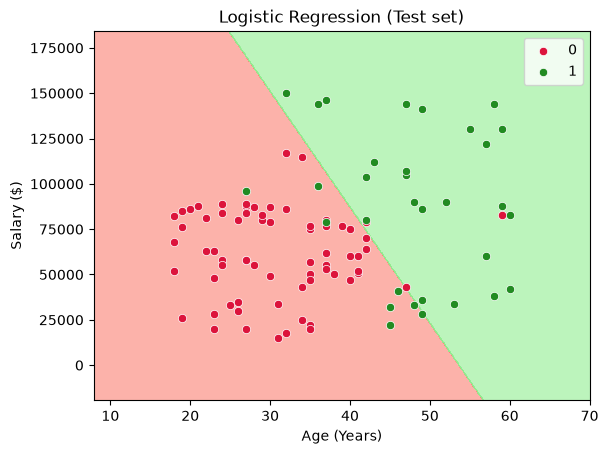

In [67]:
#Please write the code here

X_set, y_set = X_test, y_test

# Create the meshgrid on the scaled data (which the model requires for prediction)
X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, stop = X_set[:, 0].max() + 1, step = 0.01),
                     np.arange(start = X_set[:, 1].min() - 1, stop = X_set[:, 1].max() + 1, step = 0.01))

# Generate predictions for the contour plot using the scaled grid
Z = classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape)

# Inverse transform the meshgrid and test points back to original Age/Salary units for plotting
grid_points_unscaled = sc.inverse_transform(np.c_[X1.ravel(), X2.ravel()])
X1_unscaled = grid_points_unscaled[:, 0].reshape(X1.shape)
X2_unscaled = grid_points_unscaled[:, 1].reshape(X2.shape)
X_set_unscaled = sc.inverse_transform(X_set)

# Plot decision boundary using unscaled grid
plt.contourf(X1_unscaled, X2_unscaled, Z,
             alpha = 0.6, cmap = ListedColormap(('salmon', 'lightgreen')))
plt.xlim(X1_unscaled.min(), X1_unscaled.max())
plt.ylim(X2_unscaled.min(), X2_unscaled.max())

# Scatter plot using unscaled test points
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(X_set_unscaled[y_set == j, 0], X_set_unscaled[y_set == j, 1],
                color = ListedColormap(('crimson', 'forestgreen'))(i), label = j, 
                edgecolor='white', linewidth=0.5)

plt.title('Logistic Regression (Test set)')
plt.xlabel('Age (Years)')
plt.ylabel('Salary ($)')
plt.legend()
plt.show()

## IV. Reflection Questions 
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

1) Even though logistic regression outputs probabilities, because the final classification is decided by the percatage chance between 0 and 1, this becomes a strictly binary desicion that is either 1 or 0 that was based on the underlying probability score. 

2) It looks like more older people with higher income are more likely to purchase a car. There are almost no people below 30 that bought a car in this dataset. 

3) A factor that can affect the accuracy in this task is what income do these people report. Because the income they say could be joint or separate or they may even not disclose all of their income streams. This introduces noise into the dataset. The model will learn the flawed patterns and reduce its predictive accuracy.

4) To combat self reporting bias, it is important to implement a salary verification system using third party financial APIs like plaid. This would ensure the model is trained on only real and accurate data, meaning it could be even more accurate. We can also add preprocessing that removes outliers like unemployed or very rich people.